<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab8_1_KMeans_LagunaJunin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Portada CDA](https://lh3.googleusercontent.com/d/1U9hCpCqZyqnCwjMACrD_YgUdJSNPrEFZ=s1920)

# Aprendizaje No Supervisado y Agrupamiento K-Means
## Ciencia de Datos Ambientales – Clasificación de la Laguna Junín

**Duración:** 75 minutos

Referencia: [documentación de Clustering en scikit-learn](https://scikit-learn.org/stable/modules/clustering.html)

---

### Objetivos de aprendizaje

1. Distinguir aprendizaje supervisado del no supervisado y explicar cuándo es apropiado cada uno.
2. Describir el algoritmo K-Means paso a paso.
3. Implementar K-Means en `scikit-learn` e interpretar los resultados.
4. Usar el Método del Codo y el Índice de Silueta para elegir $k$.
5. Reconocer las limitaciones de K-Means.
6. Aplicar K-Means para clasificación no supervisada de imágenes satelitales peruanas — caso real: **Laguna Junín**.

> **Tarea:** al final de este notebook aplicarás el mismo flujo de trabajo para clasificar un **glaciar peruano**.

## 1. El Giro: De Etiquetas a Descubrimiento

En los Labs 7_1 a 7_4, todos los algoritmos que usamos eran **supervisados** — teníamos datos de entrenamiento etiquetados.

Pero, ¿qué pasa si **no tienes etiquetas**?

| Escenario | ¿Etiquetas? | Enfoque |
|-----------|-------------|--------|
| "Clasificar este pixel como bosque, agua o urbano" | Sí — recopilaste muestras de campo | Supervisado (SVM, KNN, NB) |
| "Tengo 10,000 pixeles — ¿existen grupos naturales que no he notado?" | No hay etiquetas | **No supervisado** |
| "Tengo un nuevo sensor satelital — ¿qué clases espectrales existen?" | Sin conocimiento previo | **No supervisado** |

En el aprendizaje no supervisado, el algoritmo descubre la **estructura** de los datos por sí mismo, sin necesidad de etiquetas proporcionadas por humanos.

### Ejemplos prácticos donde el aprendizaje no supervisado brilla

- **Análisis de comunidades ecológicas:** Se estudian 200 parcelas de pradera y se miden 50 especies de plantas. ¿Existen distintos tipos de comunidades o se trata de un continuo? El análisis de agrupamiento puede revelar grupos.

- **Teledetección:** Antes de realizar una clasificación supervisada, es necesario saber cuántas clases espectralmente distintas existen en la imagen. La clasificación no supervisada puede proporcionar esta información.

- **Detección de anomalías:** Se pueden identificar lecturas inusuales de sensores en una torre de flujo que podrían indicar un mal funcionamiento del instrumento.

- **Segmentación de clientes, análisis de expresión génica, agrupamiento de documentos...** — las mismas ideas funcionan en diversos ámbitos.

## 2. ¿Qué es el Agrupamiento (Clustering)?

El **agrupamiento** es la tarea de aprendizaje no supervisado más común: agrupar puntos de datos de manera que los puntos dentro del mismo grupo sean **más similares entre sí** que con los puntos de otros grupos.

Imagínese lo siguiente: vacíe una bolsa de caramelos surtidos sobre una mesa. Sin que nadie le diga los nombres de los caramelos, los clasificaría naturalmente en montones por color, forma y tamaño. Eso es la agrupación.

La pregunta clave es: **¿qué significa "similar"?** Para datos numéricos, la similitud generalmente se define por la **distancia** (euclidiana, de Manhattan, etc.), el mismo concepto que usamos en KNN.

## 3. K-Means: La Intuición

### La analogía de la fiesta

Imagina que organizas un gran picnic al aire libre para 100 invitados en un parque. Necesitas instalar **$k$ estaciones de comida** para que ningún invitado tenga que caminar demasiado para conseguir comida. ¿Dónde las colocas?

1. **Empieza adivinando:** Coloca $k$ estaciones de comida en lugares aleatorios del parque.

2. **Asigna invitados:** Cada invitado camina hasta la estación de comida **más cercana**.

3. **Ajusta las estaciones:** Mueve cada estación de comida al **centro** de los invitados asignados; esto minimiza la distancia total a pie.

4. **Repite:** Puede que ahora los invitados estén más cerca de otra estación, así que reasigna y vuelve a centrar. Continúa hasta que nadie cambie de estación.

¡Eso es K-Means! Sustituye "invitados" por "puntos de datos" y "estaciones de comida" por "centroides de clúster".

## 4. El Algoritmo K-Means

Formalmente, dados $N$ puntos de datos y un número deseado de clústeres $k$:

**Paso 1 – Inicializar:** Colocar aleatoriamente $k$ centroides $\boldsymbol{\mu}_1, \ldots, \boldsymbol{\mu}_k$.

**Paso 2 – Asignar:** Asignar cada punto $\mathbf{x}_i$ al centroide más cercano:
$$c_i = \arg\min_j \; \|\mathbf{x}_i - \boldsymbol{\mu}_j\|^2$$

**Paso 3 – Actualizar:** Recalcular cada centroide como la media de todos los puntos asignados:
$$\boldsymbol{\mu}_j = \frac{1}{|C_j|} \sum_{\mathbf{x}_i \in C_j} \mathbf{x}_i$$

**Paso 4 – Repetir** hasta convergencia.

El algoritmo minimiza la **suma de cuadrados intra-cluster (WCSS)**, también llamada **inercia**:
$$\text{WCSS} = \sum_{j=1}^{k} \sum_{\mathbf{x}_i \in C_j} \|\mathbf{x}_i - \boldsymbol{\mu}_j\|^2$$

Veamos cómo sucede esto paso a paso.

### Observando la convergencia de K-Means

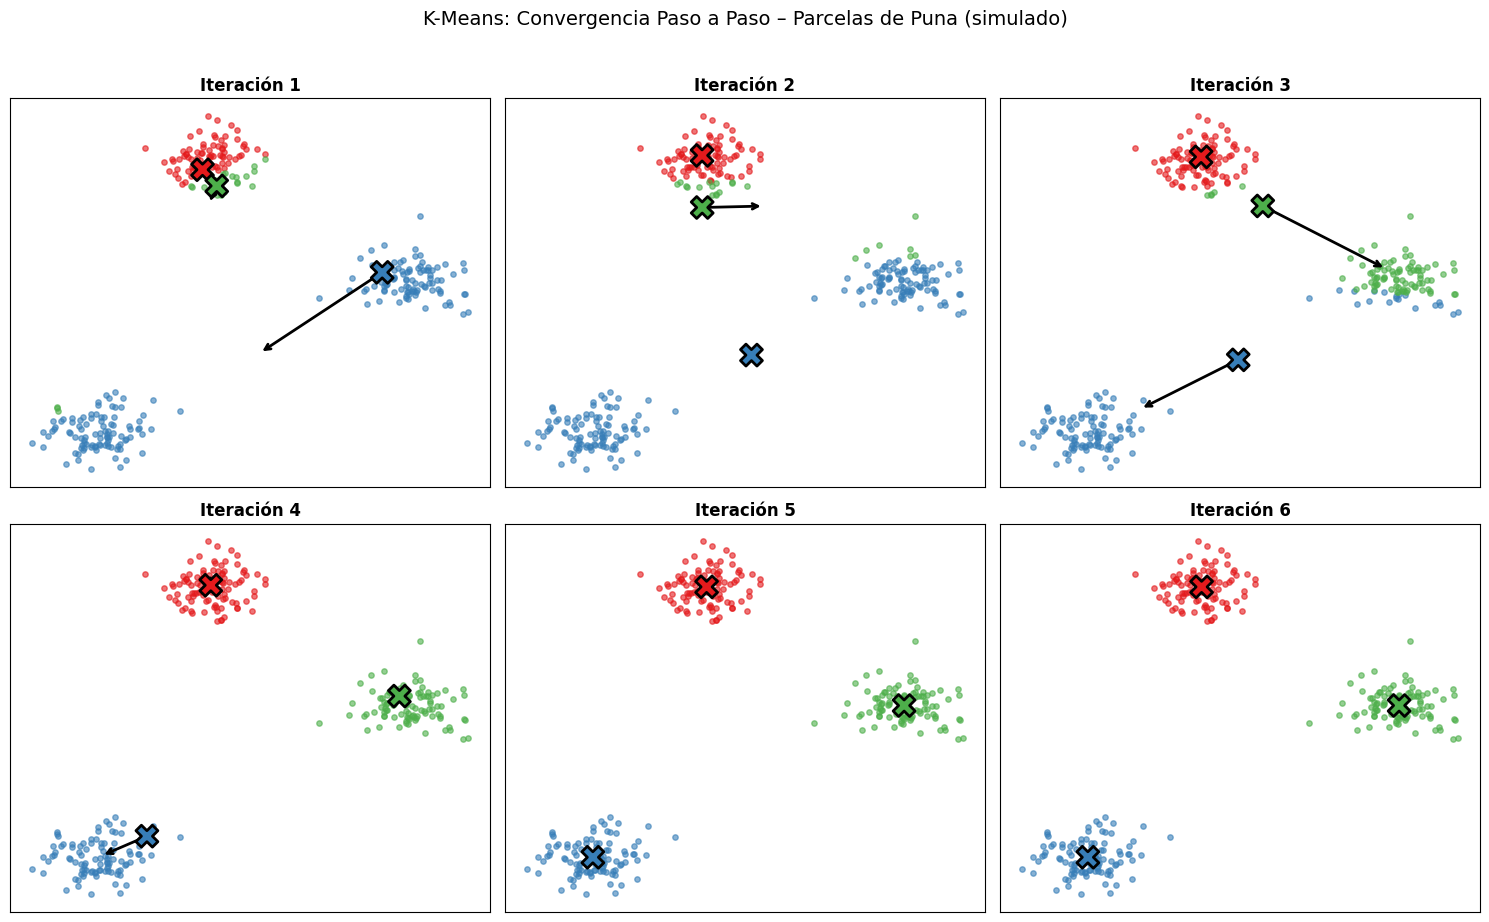

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Simular datos de parcelas de puna con 3 tipos de comunidad
np.random.seed(42)
X, y_verdad = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Implementación manual paso a paso
k = 3

# Paso 1: Random initialization
rng = np.random.RandomState(10)
centroides = X[rng.choice(len(X), k, replace=False)]

fig, ejes = plt.subplots(2, 3, figsize=(15, 9))
ejes = ejes.ravel()
colores = ['#e41a1c', '#377eb8', '#4daf4a']

for iteracion in range(6):
    ax = ejes[iteracion]

     # Paso 2: Asignación de cada punto al centroide más cercano
    distancias = np.array([np.linalg.norm(X - c, axis=1) for c in centroides])
    etiquetas  = distancias.argmin(axis=0)

    for j in range(k):
        mask = etiquetas == j
        ax.scatter(X[mask, 0], X[mask, 1], c=colores[j], s=15, alpha=0.6)

    ax.scatter(centroides[:, 0], centroides[:, 1], c=colores[:k],
               s=250, marker='X', edgecolors='k', linewidths=2, zorder=5)

    ax.set_title(f'Iteración {iteracion + 1}', fontsize=12, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

    # Step 3: Actualizar centroides
    nuevos_centroides = np.array([X[etiquetas == j].mean(axis=0) for j in range(k)])

    for viejo, nuevo in zip(centroides, nuevos_centroides):
        if np.linalg.norm(nuevo - viejo) > 0.05:
            ax.annotate('', xy=nuevo, xytext=viejo,
                        arrowprops=dict(arrowstyle='->', color='black', linewidth=2,
                                        shrinkA=5, shrinkB=5))
    centroides = nuevos_centroides

plt.suptitle('K-Means: Convergencia Paso a Paso – Parcelas de Puna (simulado)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Cada panel muestra una iteración. Las grandes marcas **X** representan los centroides, y las flechas indican cómo se mueven hacia el centro de sus puntos asignados. En las iteraciones 3 y 4, los centroides apenas se mueven: el algoritmo ha convergido.

Cabe destacar que K-Means identificó los tres clústeres sin necesidad de conocer las etiquetas reales; descubrió la estructura únicamente a partir de los datos.

## 5. K-Means en `scikit-learn`

En la práctica, no es necesario implementar K-Means manualmente: `scikit-learn` se encarga de la inicialización, la convergencia y los múltiples reinicios por usted.

Tamaños de grupos: [100 100 100]
Inercia (WCSS): 566.9
Centroides:
[[-2.63  9.04]
 [-6.88 -6.98]
 [ 4.75  2.01]]


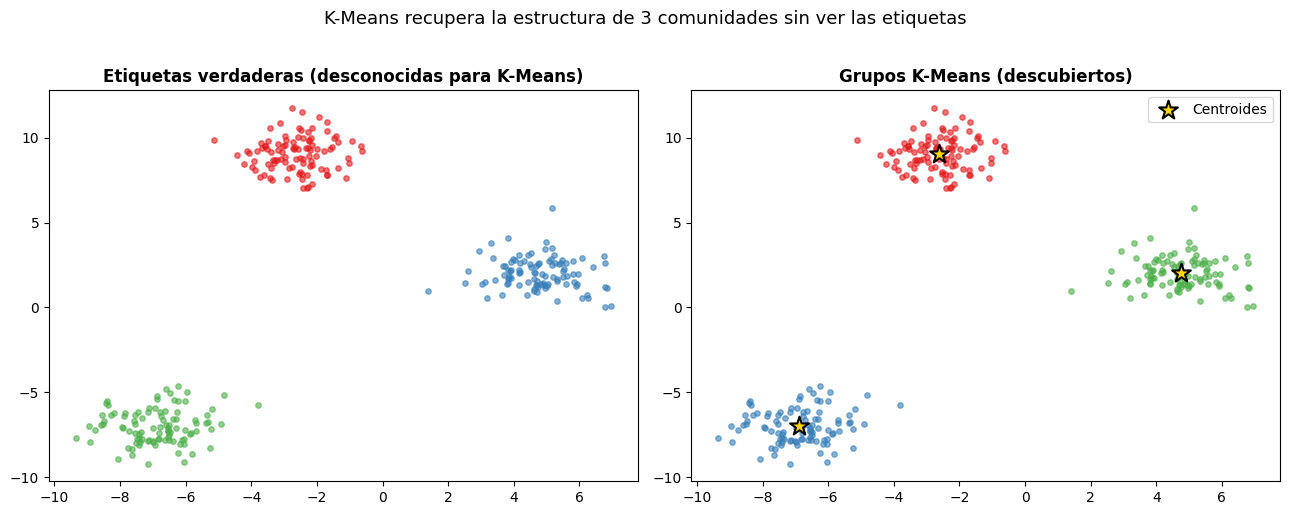

In [ ]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
import numpy as np

# Ajustar K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X)

etiquetas   = kmeans.labels_
centroides  = kmeans.cluster_centers_
inercia     = kmeans.inertia_

print(f"Tamaños de grupos: {np.bincount(etiquetas)}")
print(f"Inercia (WCSS): {inercia:.1f}")
print(f"Centroides:\n{centroides.round(2)}")

# Comparar etiquetas verdaderas vs. descubiertas
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

for ax, labs, titulo in zip(ejes,
                             [y_verdad, etiquetas],
                             ['Etiquetas verdaderas (desconocidas para K-Means)', 'Grupos K-Means (descubiertos)']):
    for j in range(3):
        mask = labs == j
        ax.scatter(X[mask, 0], X[mask, 1], c=colores[j], s=15, alpha=0.6)
    ax.set_title(titulo, fontweight='bold')

ejes[1].scatter(centroides[:, 0], centroides[:, 1], c='gold', s=200,
                marker='*', edgecolors='k', linewidths=1.5, zorder=5, label='Centroides')
ejes[1].legend()

plt.suptitle('K-Means recupera la estructura de 3 comunidades sin ver las etiquetas', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Los colores de los clústeres pueden estar permutados (K-Means no sabe qué clúster es el "clúster 0" y cuál el "clúster 1"), pero las agrupaciones coinciden con la estructura real.

## 6. Elección de $k$: ¿Cuántos clústeres?

K-Means requiere especificar $k$ de antemano, pero ¿cómo saber el número correcto de clústeres? Dos métodos ampliamente utilizados:

### Método 1: El método del codo (elbow method)

Grafique la **inercia (WCSS)** en función de $k$. A medida que $k$ aumenta, la inercia siempre disminuye (más clústeres = ajuste más preciso). El "codo" es el punto donde agregar más clústeres deja de proporcionar una mejora significativa; ese es un buen valor de $k$.

### Método 2: Puntuación de silueta

La **puntuación de silueta** (**silhouette score**) mide la similitud de cada punto con su propio clúster en comparación con el clúster vecino más cercano. Varía de $-1$ (clúster incorrecto) a $+1$ (agrupación perfecta). Cuanto mayor sea el valor, mejor.

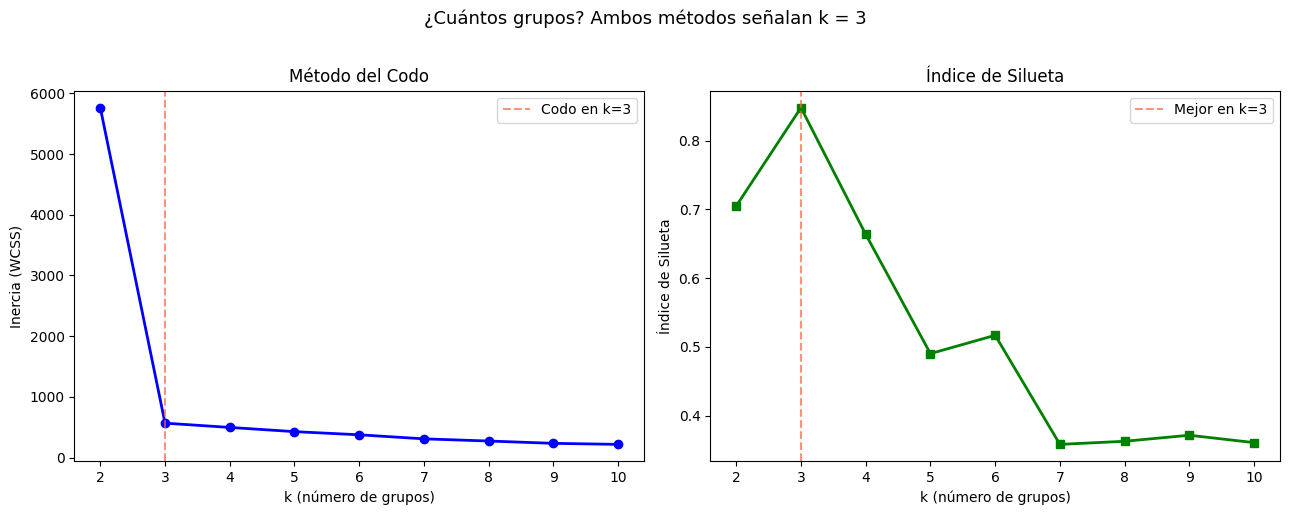

In [ ]:
from sklearn.metrics import silhouette_score

rango_k   = range(2, 11)
inercias  = []
siluetas  = []

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, km.labels_))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

# Método del Codo
ejes[0].plot(list(rango_k), inercias, 'bo-', linewidth=2)
ejes[0].axvline(3, color='tomato', linestyle='--', alpha=0.7, label='Codo en k=3')
ejes[0].set_xlabel('k (número de grupos)')
ejes[0].set_ylabel('Inercia (WCSS)')
ejes[0].set_title('Método del Codo')
ejes[0].legend()

# Índice de Silueta
ejes[1].plot(list(rango_k), siluetas, 'gs-', linewidth=2)
ejes[1].axvline(3, color='tomato', linestyle='--', alpha=0.7, label='Mejor en k=3')
ejes[1].set_xlabel('k (número de grupos)')
ejes[1].set_ylabel('Índice de Silueta')
ejes[1].set_title('Índice de Silueta')
ejes[1].legend()

plt.suptitle('¿Cuántos grupos? Ambos métodos señalan k = 3', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Para nuestros datos sintéticos, ambos métodos apuntan claramente a $k = 3$. En datos reales, la diferencia suele ser menos pronunciada: utilice ambos métodos conjuntamente y combínelos con el conocimiento del dominio (por ejemplo, "esperamos entre 4 y 6 clases de cobertura del suelo en esta región").

### ¿Qué sucede con el $k$ incorrecto?

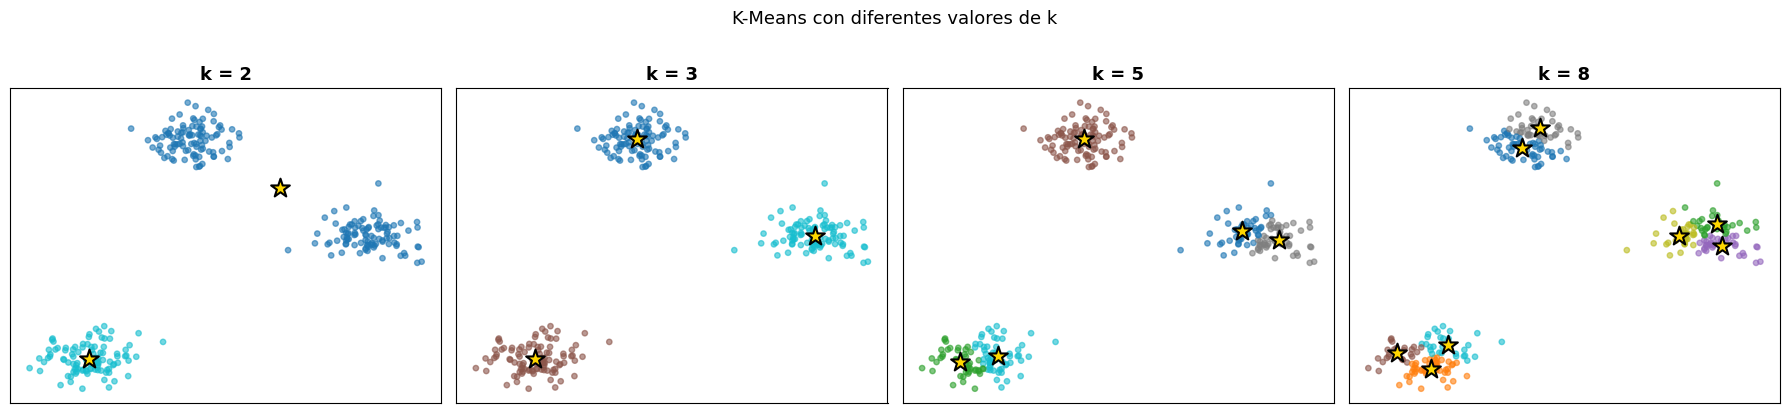

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, k in zip(axes, [2, 3, 5, 8]):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    ax.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap='tab10', s=15, alpha=0.6)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               c='gold', s=200, marker='*', edgecolors='k', linewidth=1.5, zorder=5)
    ax.set_title(f'k = {k}', fontsize=13, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('K-Means con diferentes valores de k', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

---
## 7. Cuando K-Means tiene dificultades

K-Means se basa en ciertas suposiciones importantes. Cuando estas suposiciones no se cumplen, puede fallar estrepitosamente.

### Suposición 1: Los clústeres son esféricos (isotrópicos)

K-Means asigna los puntos al centroide más cercano mediante la distancia euclidiana, lo que implica que los clústeres son aproximadamente **redondos**. Los clústeres alargados, en forma de anillo o irregulares incumplen esta suposición.

### Suposición 2: Los clústeres tienen un tamaño similar

K-Means tiende a producir clústeres de extensión espacial aproximadamente igual. Si un clúster es mucho más grande o denso que otro, K-Means puede dividir el clúster grande y fusionar los pequeños.

### Suposición 3: Se conoce $k$ de antemano

En los datos ecológicos, el número "real" de grupos suele ser desconocido o incluso puede no ser un número bien definido.

Veamos qué sucede con datos no esféricos:

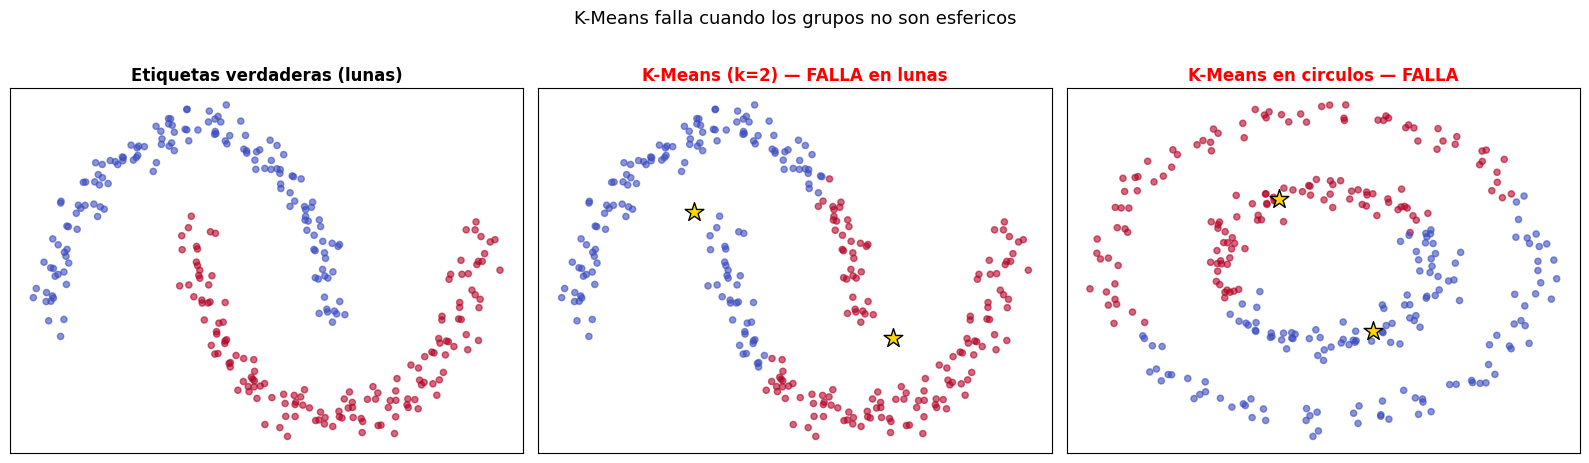

Para formas no convexas se necesitan DBSCAN o clustering espectral.


In [ ]:
from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt, numpy as np

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))

# ── Media Lunas ──
X_lunas, y_lunas = make_moons(n_samples=300, noise=0.06, random_state=42)
km_lunas = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_lunas)

ejes[0].scatter(X_lunas[:,0], X_lunas[:,1], c=y_lunas, cmap='coolwarm', s=20, alpha=0.6)
ejes[0].set_title('Etiquetas verdaderas (lunas)', fontweight='bold')

ejes[1].scatter(X_lunas[:,0], X_lunas[:,1], c=km_lunas.labels_, cmap='coolwarm', s=20, alpha=0.6)
ejes[1].scatter(*km_lunas.cluster_centers_.T, c='gold', s=200, marker='*', edgecolors='k', zorder=5)
ejes[1].set_title('K-Means (k=2) — FALLA en lunas', color='red', fontweight='bold')

# ── Ciruculos concentricos ──
X_circ, y_circ = make_circles(n_samples=300, factor=0.5, noise=0.05, random_state=42)
km_circ = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_circ)
ejes[2].scatter(X_circ[:,0], X_circ[:,1], c=km_circ.labels_, cmap='coolwarm', s=20, alpha=0.6)
ejes[2].scatter(*km_circ.cluster_centers_.T, c='gold', s=200, marker='*', edgecolors='k', zorder=5)
ejes[2].set_title('K-Means en circulos — FALLA', color='red', fontweight='bold')

for ax in ejes: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('K-Means falla cuando los grupos no son esfericos', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

print("Para formas no convexas se necesitan DBSCAN o clustering espectral.")

K-Means divide tanto las lunas como los círculos con un corte vertical, ya que solo puede trazar límites basados ​​en la distancia a los centroides. Para formas no convexas como estas, se necesitarían algoritmos como **DBSCAN** o **agrupamiento espectral** (que están fuera del alcance de este curso, pero es bueno saber que existen).

> **Conclusión ecológica:** K-Means funciona bien para clases de cobertura terrestre espectralmente distintas (que tienden a formar manchas en el espacio de características espectrales), pero puede tener dificultades con gradientes o ecotonos donde las comunidades se mezclan entre sí.

## 8. Aplicación ecológica: Clasificación no supervisada de imágenes satelitales

Uno de los usos más comunes del algoritmo K-Means en ciencias ambientales es la **clasificación no supervisada** de imágenes satelitales. En lugar de proporcionar muestras de entrenamiento, se deja que el algoritmo descubra las clases espectralmente distintas en la imagen.

Esto resulta útil cuando:
- No se dispone de datos de referencia/entrenamiento.

- Se desea explorar las clases espectrales existentes antes de realizar una clasificación supervisada.

- Se necesita una primera evaluación rápida de una nueva área de estudio.

### K-Means en datos espectrales de Landsat

Simulemos esto con datos espectrales reales a escala de Landsat. Crearemos "píxeles" sintéticos que imitan las firmas espectrales de cuatro tipos de cobertura terrestre:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# ── Simular firmas espectrales tipo Landsat para 4 tipos de cobertura terrestre ──
# Cada píxel tiene 6 bandas: Azul, Verde, Rojo, NIR, SWIR1, SWIR2
# Los valores son reflectancia superficial * 10000

n_per_class = 200

# Agua: baja en todas las bandas, especialmente en NIR
agua = np.random.normal(
    loc=[800, 900, 700, 400, 200, 150],
    scale=[100, 100, 100, 80, 50, 40],
    size=(n_per_class, 6)
)

# Bosque: visibilidad baja, infrarrojo cercano (NIR) muy alto, infrarrojo de onda corta (SWIR) moderado
bosque = np.random.normal(
    loc=[500, 600, 400, 3500, 1800, 800],
    scale=[80, 80, 80, 400, 300, 150],
    size=(n_per_class, 6)
)

# Agricultura: visibilidad moderada, NIR alto (pero menor que el bosque), SWIR alto
agricultura = np.random.normal(

    loc=[700, 800, 650, 2800, 2200, 1200],
    scale=[100, 100, 100, 350, 350, 200],
    size=(n_per_class, 6)
)
# Suelo urbano/desnudo: alta visibilidad, NIR moderada, SWIR alta
urbano = np.random.normal(
    loc=[1200, 1300, 1400, 1800, 2500, 2200],
    scale=[200, 200, 200, 300, 400, 350],
    size=(n_per_class, 6)
)
X_espectral = np.vstack([agua, bosque, agricultura, urbano])
y_espectral_verdadero = np.array([0]*n_per_class + [1]*n_per_class +

[2]*n_per_class + [3]*n_per_class)
nombres_banda = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']
class_names = ['Agua', 'Bosque', 'Agricultura', 'Urbano']

print(f"Se simularon {len(X_espectral)} píxeles con {X_espectral.shape[1]} bandas espectrales")
print(f"Clases verdaderas: {', '.join(class_names)}")

Se simularon 800 píxeles con 6 bandas espectrales
Clases verdaderas: Agua, Bosque, Agricultura, Urbano


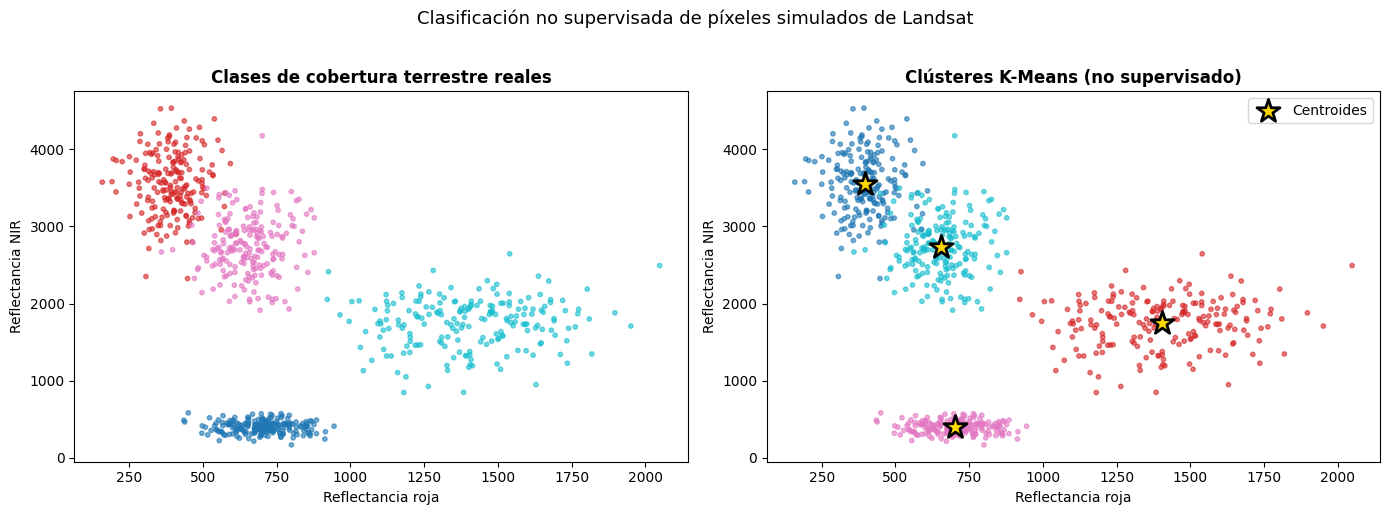

In [ ]:
# ── Ejecutar K-Means (sin supervisión — ¡sin etiquetas!) ──
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_espectral)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_scaled)
pred_labels = kmeans.labels_

# ── Comparar: etiquetas reales vs. clústeres de K-Means ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#1f78b4', '#33a02c', '#ffff99', '#e31a1c']
cmap_true = plt.cm.colors.ListedColormap(colors)

# Graficar en el espacio NIR vs. rojo (ejes clásicos de teledetección)
nir_idx, red_idx = 3, 2

for ax, labels_arr, title in zip(axes,
    [y_espectral_verdadero, pred_labels],
    ['Clases de cobertura terrestre reales', 'Clústeres K-Means (no supervisado)']):
    scatter = ax.scatter(X_espectral[:, red_idx], X_espectral[:, nir_idx],
    c=labels_arr, cmap='tab10', s=10, alpha=0.6)
    ax.set_xlabel('Reflectancia roja')
    ax.set_ylabel('Reflectancia NIR')
    ax.set_title(title, fontweight='bold')

# Agregar Gráfico de centroides a K-Means (transformación a la escala original)
centroids_orig = scaler.inverse_transform(kmeans.cluster_centers_)
axes[1].scatter(centroids_orig[:, red_idx], centroids_orig[:, nir_idx],
c='gold', s=300, marker='*', edgecolors='k', linewidths=2, zorder=5,

label='Centroides')
axes[1].legend()

plt.suptitle('Clasificación no supervisada de píxeles simulados de Landsat',

fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

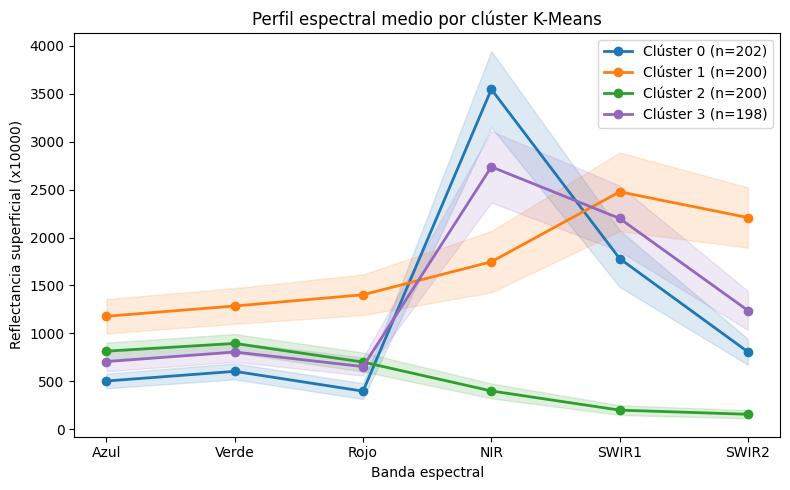

Interpretación de los clústeres según sus firmas espectrales:
 - Baja en todas las bandas, especialmente en el infrarrojo cercano (NIR) → Agua
 - Baja en el visible, muy alta en el NIR → Bosque (vegetación sana)
 - Moderada en el NIR, alta en el infrarrojo de onda corta (SWIR) → Agricultura
 - Alta en el visible, alta en el SWIR → Urbano / suelo desnudo


In [ ]:
# ── Perfiles espectrales de cada clúster K-Means ──
fig, ax = plt.subplots(figsize=(8, 5))
cluster_colors = plt.cm.tab10(np.linspace(0, 0.4, 4))
for j in range(4):
    mask = pred_labels == j
    mean_spectrum = X_espectral[mask].mean(axis=0)
    std_spectrum = X_espectral[mask].std(axis=0)

    ax.plot(nombres_banda, mean_spectrum, 'o-', color=cluster_colors[j],
            linewidth=2, label=f'Clúster {j} (n={mask.sum()})')
    ax.fill_between(nombres_banda,
                    mean_spectrum - std_spectrum,
                    mean_spectrum + std_spectrum,
                    color=cluster_colors[j], alpha=0.15)

ax.set_xlabel('Banda espectral')
ax.set_ylabel('Reflectancia superficial (x10000)')
ax.set_title('Perfil espectral medio por clúster K-Means')
ax.legend()
plt.tight_layout()
plt.show()

print("Interpretación de los clústeres según sus firmas espectrales:")
print(" - Baja en todas las bandas, especialmente en el infrarrojo cercano (NIR) → Agua")
print(" - Baja en el visible, muy alta en el NIR → Bosque (vegetación sana)")
print(" - Moderada en el NIR, alta en el infrarrojo de onda corta (SWIR) → Agricultura")
print(" - Alta en el visible, alta en el SWIR → Urbano / suelo desnudo")

### Paso de interpretación

K-Means proporciona números de clúster (0, 1, 2, 3), no nombres de clases. **Debes** interpretar qué representa cada clúster examinando los perfiles espectrales, comparándolos con firmas conocidas o superponiendo el resultado sobre imágenes de alta resolución. Esta es la diferencia clave con la clasificación supervisada: el algoritmo encuentra grupos, pero el humano les da significado.

En GEE, el flujo de trabajo de clasificación no supervisada es:

```python
# Agrupar la imagen en k clases espectrales
training = image.sample(region=study_area, scale=30, numPixels=5000)
clusterer = ee.Clusterer.wekaKMeans(4).train(training)
result = image.cluster(clusterer)
```

> **Ejercicio:** Prueba esto con tu área de estudio en GEE. ¿Cómo se comparan los clústeres no supervisados ​​con las clases supervisadas?

---
## 9. Detalles prácticos

### La inicialización es importante: K-Means++

Una inicialización aleatoria puede generar malos resultados si los centroides se encuentran en posiciones desfavorables. **K-Means++** es una inicialización más inteligente que distribuye los centroides iniciales:

1. Se elige el primer centroide aleatoriamente.

2. Para cada centroide restante, se elige el punto que está **más alejado** del centroide existente más cercano (ponderado por la distancia al cuadrado).

Esto garantiza que los centroides se encuentren en diferentes partes de los datos. `scikit-learn` utiliza K-Means++ por defecto (`init='k-means++'`).

### Reinicios múltiples

Incluso con K-Means++, diferentes semillas aleatorias pueden dar resultados distintos. El parámetro `n_init` (valor predeterminado = 10) ejecuta el algoritmo 10 veces con diferentes inicializaciones y conserva el mejor resultado (menor inercia).

### Escalado de características

Al igual que KNN y SVM con núcleos RBF, K-Means utiliza la distancia euclidiana; por lo tanto, **el escalado de características es esencial**. Siempre estandarice o normalice antes de agrupar.

---
## 10. Mas alla de K-Means

K-Means es el mas popular, pero no el unico:

| Algoritmo | Forma de grupos | Necesita k | Fortalezas |
|-----------|-----------------|------------|------------|
| **K-Means** | Esferico | Si | Rapido, escalable |
| **Jerarquico** | Cualquiera | No (cortar dendrograma) | Arbol de grupos; muy usado en ecologia |
| **DBSCAN** | Cualquiera (densidad) | No | Formas arbitrarias; maneja ruido |
| **Mezcla Gaussiana** | Eliptico | Si | Asignaciones blandas (probabilidades) |

En la investigación ecológica, el **agrupamiento jerárquico** es particularmente común; es posible que hayas visto dendrogramas en artículos sobre ecología de comunidades. La elección depende de tus datos y de tu pregunta de investigación.

---
## 11. Caso Real: K-Means sobre imagen Sentinel-2 — Laguna Junín

Repetimos el mismo análisis pero con **píxeles reales** de un composito Sentinel-2 sobre la **Laguna Junín** (Lago Chinchaycocha), el segundo lago más grande del Perú, ubicado en la puna a ~4080 msnm en la región Junín. Es un humedal Ramsar rodeado de **bofedales** (vegetación acuática altoandina) y **pastizales de puna**, con cierta influencia del corredor minero La Oroya–Cerro de Pasco al sur.

Ahora no sabemos de antemano cuántas clases existen — el codo y la silueta nos ayudan a elegir `k`.

In [ ]:
# AUTENTICACIÓN (Ejecute esta celda y siga las instrucciones)
# Esto abrirá una ventana del navegador donde deberá iniciar sesión en Google y otorgar permiso
# para que este cuaderno acceda a Earth Engine. Solo necesita hacer esto una vez por sesión.
import ee, geemap
ee.Authenticate()
ee.Initialize(project='utec-ingambiental-01')  # <-- REEMPLAZA con tu Project ID utec-ingambiental-01 ee-cmillanarancibia

# Área de estudio: Laguna Junín (Lago Chinchaycocha) — región Junín, Perú, ~4080 msnm
# Segundo lago más grande del Perú; humedal Ramsar rodeado de bofedales y pastizales de puna
area_estudio = ee.Geometry.Rectangle([
    -76.27178926829023, -11.13708745225072,   # esquina suroeste (lon_min, lat_min)
    -75.99369783762617, -10.854665283162186   # esquina noreste  (lon_max, lat_max)
])


# Composito Sentinel-2, época seca 2026 (mayo–septiembre: menor nubosidad en la sierra)
sentinel = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
composito = (
    sentinel
    .filterBounds(area_estudio)
    .filterDate('2025-05-01', '2025-09-30')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30))
    .select(['B2','B3','B4','B8','B11','B12'])
)

# Median composite (reduces remaining cloud artifacts)
composito = composito.median().clip(area_estudio)

In [ ]:
# Los datos de la Colección 2 de Sentinel-2 requieren escalado.
# Los valores brutos son enteros; necesitamos convertirlos a reflectancia (0-1).

# Aplicar factores de escala
def escalar(img):
    """
    Aplicar factores de escala a la reflectancia superficial de la Colección 2 de Sentinel-2.
    La fórmula es: reflectancia = DN * 0.0001
    .multiply(0.0001)  # Escalar a reflectancia
    Esto convierte los números enteros almacenados en valores de reflectancia reales.
    """

    bandas_opt = ['B2','B3','B4','B8','B11','B12']
    opt = img.select(bandas_opt)

    escalada = opt.multiply(0.0001)
    return img.addBands(escalada, overwrite=True)

composito = escalar(composito)
print("Imagen escalada a valores de reflectancia (0–1)")

composito = composito.select(['B2','B3','B4','B8','B11','B12'],['Azul','Verde','Rojo','NIR','SWIR1','SWIR2'])

Imagen escalada a valores de reflectancia (0–1)


In [ ]:
Map = geemap.Map(basemap="Esri.WorldTopoMap")
Map.centerObject(area_estudio, zoom=12)
Map.addLayer(composito,
             {'bands':['Rojo','Verde','Azul'],'min':0,'max':0.35},
             'Composito Sentinel-2 — Laguna Junín')
Map

Map(center=[-10.995885416319076, -76.13274355295805], controls=(WidgetControl(options=['position', 'transparen…

Muestreando píxeles del composito Sentinel-2...
Píxeles muestreados: 3000

Estadísticas de reflectancia:
            Azul      Verde       Rojo        NIR      SWIR1      SWIR2
count  3000.0000  3000.0000  3000.0000  3000.0000  3000.0000  3000.0000
mean      0.0396     0.0633     0.0748     0.1961     0.1932     0.1176
std       0.0250     0.0352     0.0443     0.1206     0.1268     0.0812
min       0.0000     0.0031     0.0000     0.0000     0.0011     0.0004
25%       0.0180     0.0337     0.0419     0.1010     0.0726     0.0438
50%       0.0406     0.0680     0.0805     0.2261     0.2352     0.1264
75%       0.0569     0.0875     0.1067     0.2900     0.3018     0.1849
max       0.2279     0.2931     0.2974     0.4676     0.4471     0.3672


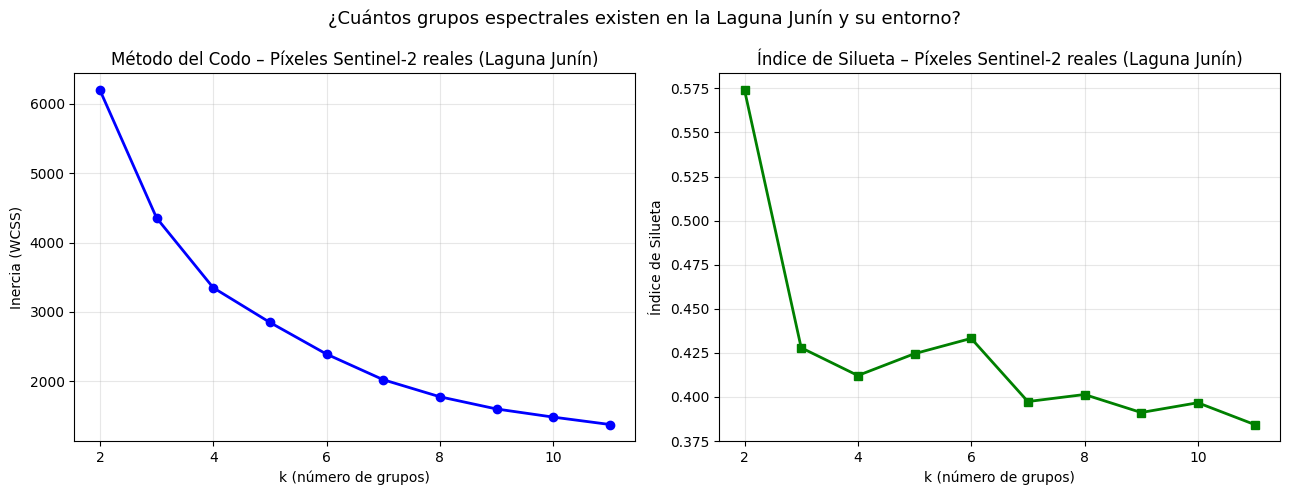

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Muestrear píxeles del composito real Sentinel-2
bandas = ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2']

print("Muestreando píxeles del composito Sentinel-2...")
muestra = composito.sample(
    region=area_estudio,
    scale=10,
    numPixels=3000,
    seed=42
)

info = muestra.getInfo()
df_px = pd.DataFrame([f['properties'] for f in info['features']])[bandas].dropna()
X_real = df_px.values
print(f"Píxeles muestreados: {len(X_real)}")
print(f"\nEstadísticas de reflectancia:")
print(df_px.describe().round(4))

# Estandarizar (obligatorio: K-Means usa distancia euclidiana)
esc_real = StandardScaler()
X_real_e = esc_real.fit_transform(X_real)

# Método del codo + Silueta para elegir k
rango_k = range(2, 12)
inercias_r = []
siluetas_r = []

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_real_e)
    inercias_r.append(km.inertia_)
    siluetas_r.append(silhouette_score(X_real_e, km.labels_))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].plot(list(rango_k), inercias_r, 'bo-', linewidth=2)
ejes[0].set_xlabel('k (número de grupos)')
ejes[0].set_ylabel('Inercia (WCSS)')
ejes[0].set_title('Método del Codo – Píxeles Sentinel-2 reales (Laguna Junín)')
ejes[0].grid(True, alpha=0.3)

ejes[1].plot(list(rango_k), siluetas_r, 'gs-', linewidth=2)
ejes[1].set_xlabel('k (número de grupos)')
ejes[1].set_ylabel('Índice de Silueta')
ejes[1].set_title('Índice de Silueta – Píxeles Sentinel-2 reales (Laguna Junín)')
ejes[1].grid(True, alpha=0.3)

plt.suptitle('¿Cuántos grupos espectrales existen en la Laguna Junín y su entorno?', fontsize=13)
plt.tight_layout()
plt.show()

K-Means con k=6:
Tamaño de grupos: [946 531 776 131  26 590]


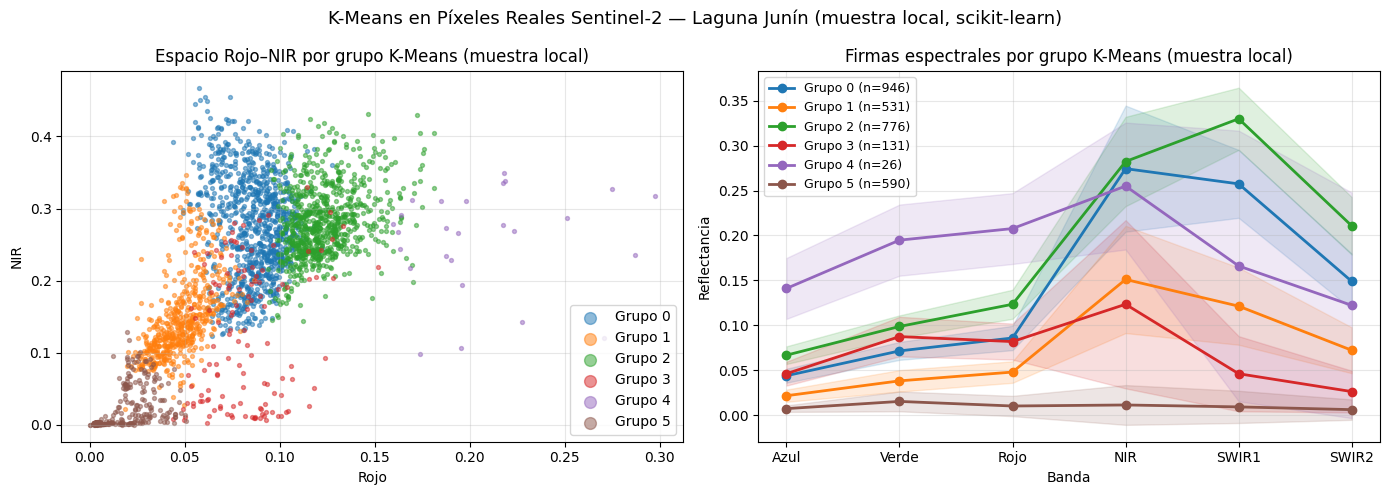

Nota: estos 'Grupo 0,1,2,3,..., k' provienen del K-Means LOCAL (scikit-learn, esta muestra).
El clusterer de GEE que clasificará la imagen completa (siguiente celda) es OTRO ajuste
independiente — su numeración de clusters puede no coincidir con la de aquí.
La interpretación definitiva (alineada con los colores del mapa) se hace después del mapa.


In [ ]:
# Elegir k según los gráficos anteriores (ajusta si el codo sugiere otro valor)
K_CLASES = 6

kmeans_real = KMeans(n_clusters=K_CLASES, random_state=42, n_init=10)
grupos = kmeans_real.fit_predict(X_real_e)

print(f"K-Means con k={K_CLASES}:")
print(f"Tamaño de grupos: {np.bincount(grupos)}")

cmap_g = plt.cm.tab10(np.linspace(0, 0.5, K_CLASES))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

# Espacio Rojo-NIR
for j in range(K_CLASES):
    mask = grupos == j
    ejes[0].scatter(X_real[mask, 2], X_real[mask, 3],
                    s=8, alpha=0.5, color=cmap_g[j], label=f'Grupo {j}')
ejes[0].set_xlabel('Rojo')
ejes[0].set_ylabel('NIR')
ejes[0].set_title('Espacio Rojo–NIR por grupo K-Means (muestra local)')
ejes[0].legend(markerscale=3)
ejes[0].grid(True, alpha=0.3)

# Firmas espectrales (media ± desv. estándar)
for j in range(K_CLASES):
    mask = grupos == j
    media = X_real[mask].mean(axis=0)
    std   = X_real[mask].std(axis=0)
    ejes[1].plot(bandas, media, 'o-', color=cmap_g[j], linewidth=2,
                 label=f'Grupo {j} (n={mask.sum()})')
    ejes[1].fill_between(bandas, media - std, media + std, color=cmap_g[j], alpha=0.15)
ejes[1].set_xlabel('Banda')
ejes[1].set_ylabel('Reflectancia')
ejes[1].set_title('Firmas espectrales por grupo K-Means (muestra local)')
ejes[1].legend(fontsize=9)
ejes[1].grid(True, alpha=0.3)

plt.suptitle('K-Means en Píxeles Reales Sentinel-2 — Laguna Junín (muestra local, scikit-learn)', fontsize=13)
plt.tight_layout()
plt.show()

print("Nota: estos 'Grupo 0,1,2,3,..., k' provienen del K-Means LOCAL (scikit-learn, esta muestra).")
print("El clusterer de GEE que clasificará la imagen completa (siguiente celda) es OTRO ajuste")
print("independiente — su numeración de clusters puede no coincidir con la de aquí.")
print("La interpretación definitiva (alineada con los colores del mapa) se hace después del mapa.")

In [ ]:
# Clasificar la imagen completa con K-Means nativo de GEE
# El clusterer de GEE procesa todos los píxeles en el servidor (sin límite de memoria local)

muestra_gee = composito.sample(
    region=area_estudio,
    scale=10,
    numPixels=1000,
    seed=42
)

clusterer = ee.Clusterer.wekaKMeans(K_CLASES).train(muestra_gee)
imagen_clusterizada = composito.cluster(clusterer)

# Una paleta por grupo (ampliable para más clases)
paleta = ['#33a02c', '#1f78b4', "#faf74f", '#a65628', '#984ea3',
          '#ff7f00', '#a65628', '#f781bf'][:K_CLASES]

Mapa_km = geemap.Map(basemap="Esri.WorldTopoMap")
Mapa_km.centerObject(area_estudio, zoom=12)
Mapa_km.addLayer(composito,
                 {'bands': ['Rojo', 'Verde', 'Azul'], 'min': 0, 'max': 0.35},
                 'Sentinel-2 RGB — Laguna Junín')
Mapa_km.addLayer(imagen_clusterizada,
                 {'min': 0, 'max': K_CLASES - 1, 'palette': paleta},
                 f'K-Means (k={K_CLASES})')
Mapa_km

Map(center=[-10.995885416319076, -76.13274355295805], controls=(WidgetControl(options=['position', 'transparen…

In [ ]:
# ── Interpretar los clusters TAL COMO aparecen en el mapa (imagen_clusterizada) ──
# Importante: el clusterer de GEE (wekaKMeans) se entrenó por separado del K-Means local
# de scikit-learn (celda anterior a la del mapa). El número de cluster 0,1,2... de cada uno
# NO tiene por qué coincidir. Para evitar interpretaciones erróneas, calculamos la firma
# espectral directamente sobre la imagen clasificada que se muestra en el mapa (Mapa_km).

imagen_con_cluster = composito.addBands(imagen_clusterizada.rename('cluster'))

reductor_agrupado = ee.Reducer.mean().repeat(len(bandas)).group(
    groupField=len(bandas), groupName='cluster'
)

stats = imagen_con_cluster.select(bandas + ['cluster']).reduceRegion(
    reducer=reductor_agrupado,
    geometry=area_estudio,
    scale=10,
    maxPixels=1e9
)

grupos_mapa = stats.get('groups').getInfo()

# Etiquetas asignadas por inspección visual de 'Mapa_km' (comparando cada cluster
# contra el composito Sentinel-2 RGB).
# podrian comparar con la clasificación de mapbiomas (https://plataforma.mapbiomas.org/coverage/coverage_lclu?t[regionKey]=peru&t[ids][]=16-1-1)
etiquetas_cluster = {
    0: 'Pastizales / Herbáceos',
    1: 'Agua',
    2: 'Pastizal',
    3: 'Suelo húmedo',
    4: 'Pradera inundada',
    5: 'Pantano / pradera inundada',
}

print("Interpretación de los clusters (asignada por inspección visual de 'Mapa_km'):\n")
for g in sorted(grupos_mapa, key=lambda d: d['cluster']):
    cluster_id = g['cluster']
    azul, verde, rojo, nir, swir1, swir2 = g['mean']
    ndvi = (nir - rojo) / (nir + rojo + 1e-8)
    etiq = etiquetas_cluster.get(cluster_id, 'Indefinido — revisar en mapa')
    print(f"  Cluster {cluster_id}  [{paleta[cluster_id]}]: "
          f"NDVI≈{ndvi:.2f}, NIR={nir:.3f}, SWIR1={swir1:.3f}  →  {etiq}")

print("\nEtiquetas confirmadas visualmente contra los colores de 'Mapa_km'.")

Interpretación de los clusters (asignada por inspección visual de 'Mapa_km'):

  Cluster 0  [#33a02c]: NDVI≈0.40, NIR=0.223, SWIR1=0.285  →  Pastizales / Herbáceos
  Cluster 1  [#1f78b4]: NDVI≈0.01, NIR=0.012, SWIR1=0.009  →  Agua
  Cluster 2  [#faf74f]: NDVI≈0.39, NIR=0.296, SWIR1=0.341  →  Pastizal
  Cluster 3  [#a65628]: NDVI≈0.49, NIR=0.144, SWIR1=0.117  →  Suelo húmedo
  Cluster 4  [#984ea3]: NDVI≈0.59, NIR=0.324, SWIR1=0.233  →  Pradera inundada
  Cluster 5  [#ff7f00]: NDVI≈0.03, NIR=0.108, SWIR1=0.029  →  Pantano / pradera inundada

Etiquetas confirmadas visualmente contra los colores de 'Mapa_km'.


### Calcular el área de cada clase

Antes de exportar la imagen, calculamos cuántos km² (y hectáreas) ocupa cada clase dentro del área de estudio. Para esto usamos `ee.Image.pixelArea()` (el área real de cada píxel en m², que en Sentinel-2 a 10 m no es exactamente 100 m² en los bordes por la proyección) y la agrupamos por el valor de `cluster` con `ee.Reducer.sum().group(...)` — el mismo patrón de agrupamiento que usamos para las firmas espectrales, pero sumando área en vez de promediar bandas.

Esto es información útil por sí misma (por ejemplo, "¿cuántos km² de espejo de agua tiene la Laguna Junín?") y la guardamos en un CSV para usarla en reportes o compararla con clasificaciones de otras fechas.

In [ ]:
# ── Calcular área (m², ha, km²) por clase antes de exportar ──
img_area_cluster = ee.Image.pixelArea().rename('area_m2').addBands(imagen_clusterizada.rename('cluster'))

reductor_area = ee.Reducer.sum().group(groupField=1, groupName='cluster')

stats_area = img_area_cluster.select(['area_m2', 'cluster']).reduceRegion(
    reducer=reductor_area,
    geometry=area_estudio,
    scale=10,
    maxPixels=1e9
)

grupos_area = stats_area.get('groups').getInfo()

filas_area = []
for g in grupos_area:
    cluster_id = g['cluster']
    area_m2 = g['sum']
    filas_area.append({
        'cluster': cluster_id,
        'clase': etiquetas_cluster.get(cluster_id, 'Indefinido — revisar en mapa'),
        'color': paleta[cluster_id],
        'area_m2': area_m2,
        'area_ha': area_m2 / 1e4,
        'area_km2': area_m2 / 1e6,
    })

df_areas = pd.DataFrame(filas_area).sort_values('cluster').reset_index(drop=True)
df_areas['porcentaje'] = 100 * df_areas['area_km2'] / df_areas['area_km2'].sum()

print(df_areas.round(2))

df_areas.to_csv('LagunaJunin_KMeans_AreasPorClase.csv', index=False)
print("\nGuardado: LagunaJunin_KMeans_AreasPorClase.csv")

   cluster                       clase    color       area_m2   area_ha  \
0        0      Pastizales / Herbáceos  #33a02c  2.083003e+08  20830.03   
1        1                        Agua  #1f78b4  1.907662e+08  19076.62   
2        2                    Pastizal  #faf74f  1.898715e+08  18987.15   
3        3                Suelo húmedo  #a65628  1.667693e+08  16676.93   
4        4            Pradera inundada  #984ea3  1.675997e+08  16759.97   
5        5  Pantano / pradera inundada  #ff7f00  2.613825e+07   2613.82   

   area_km2  porcentaje  
0    208.30       21.94  
1    190.77       20.09  
2    189.87       20.00  
3    166.77       17.56  
4    167.60       17.65  
5     26.14        2.75  

Guardado: LagunaJunin_KMeans_AreasPorClase.csv


### Exportar la imagen clasificada

Agregamos la clasificación como una banda llamada **"Clases"** a la imagen y la exportamos a Google Drive en formato GeoTIFF. Esto permite abrir el resultado en QGIS, ArcGIS o cualquier otro SIG para análisis posterior (cálculo de áreas por clase, superposición con otras capas, etc.).

In [ ]:
# ── Exportar la imagen clasificada (banda "Clases") a Google Drive ──────────
# Agregamos la clasificación de K-Means como una banda adicional llamada "Clases"
imagen_exportar = composito.addBands(imagen_clusterizada.rename('Clases'))

tarea_exportar = ee.batch.Export.image.toDrive(
    image=imagen_exportar.select(bandas + ['Clases']),
    description='LagunaJunin_KMeans_Clases',
    folder='GEE_exports',                       # <-- carpeta en tu Google Drive (se crea si no existe)
    fileNamePrefix='LagunaJunin_KMeans_Clases',
    region=area_estudio,
    scale=10,
    maxPixels=1e9
)
#tarea_exportar.start()

print("Tarea de exportación iniciada.")
print("Bandas exportadas:", bandas + ['Clases'])
print("Revisa el progreso (puede tardar varios minutos) en:")
print("  https://code.earthengine.google.com/tasks")
print("El archivo aparecerá en tu Google Drive, carpeta 'GEE_exports', como:")
print("  LagunaJunin_KMeans_Clases.tif")

Tarea de exportación iniciada.
Bandas exportadas: ['Azul', 'Verde', 'Rojo', 'NIR', 'SWIR1', 'SWIR2', 'Clases']
Revisa el progreso (puede tardar varios minutos) en:
  https://code.earthengine.google.com/tasks
El archivo aparecerá en tu Google Drive, carpeta 'GEE_exports', como:
  LagunaJunin_KMeans_Clases.tif


---
## 🔬 Ejercicio: Agrupar Cuencas Hidrográficas Peruanas

Usando datos hidrológicos sintéticos de cuencas peruanas:

1. Aplica K-Means con k=4 para agrupar las cuencas
2. Usa el método del codo para verificar si k=4 es apropiado
3. Interpreta los grupos: ¿qué tipos de régimen hidrológico representan?

> **Nota:** En hidrología peruana existen regímenes bien diferenciados: cuencas glaciares (máximo en época seca), cuencas tropicales (máximo en época lluviosa), cuencas áridas de la costa (episódico) y cuencas mixtas.

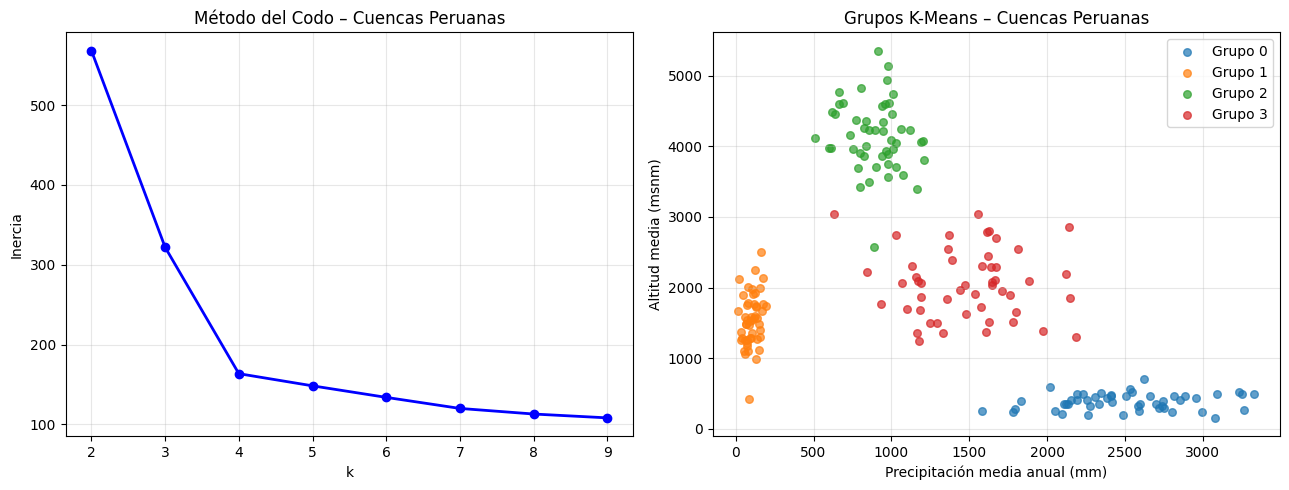


Medias por grupo (antes de escalar):
   Área (km²)  Pendiente (°)  Cobertura forestal (%)  Precipitación (mm)  \
0      2032.0            5.0                    86.0              2501.0   
1       313.0           10.0                     5.0               101.0   
2       521.0           24.0                    18.0               895.0   
3      1260.0           15.0                    59.0              1487.0   

   Altitud media (msnm)  Caudal específico  
0                 383.0               78.0  
1                1544.0                2.0  
2                4148.0               50.0  
3                2049.0               35.0  


In [ ]:
# Dataset de características de cuencas peruanas
np.random.seed(42)
n_cuencas = 200

# Variables: área (km²), pendiente media (°), cobertura forestal (%),
#            precipitación media anual (mm), altitud media (msnm), Qesp (l/s/km²)

# Cuenca glaciar andina
cuencas_glaciares = np.random.normal(
    [500, 25, 20, 900, 4200, 45], [100, 5, 10, 200, 500, 15], (50, 6))

# Cuenca amazónica tropical
cuencas_amazon = np.random.normal(
    [2000, 5, 85, 2500, 400, 80], [500, 2, 10, 400, 100, 20], (50, 6))

# Cuenca costera árida
cuencas_costa = np.random.normal(
    [300, 10, 5, 100, 1500, 2], [100, 3, 3, 50, 400, 1], (50, 6))

# Cuenca mixta andino-amazónica
cuencas_mixtas = np.random.normal(
    [1200, 15, 55, 1500, 2000, 35], [300, 5, 15, 300, 500, 10], (50, 6))

X_cuencas = np.vstack([cuencas_glaciares, cuencas_amazon, cuencas_costa, cuencas_mixtas])
X_cuencas = np.maximum(X_cuencas, 0)
nombres_vars = ['Área (km²)', 'Pendiente (°)', 'Cobertura forestal (%)',
                'Precipitación (mm)', 'Altitud media (msnm)', 'Caudal específico']

# Escalar y aplicar K-Means
esc_cuencas = StandardScaler()
X_cuencas_e = esc_cuencas.fit_transform(X_cuencas)

# Método del codo
inercias_c = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_cuencas_e).inertia_
              for k in range(2, 10)]

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

ejes[0].plot(range(2, 10), inercias_c, 'bo-', linewidth=2)
ejes[0].set_xlabel('k')
ejes[0].set_ylabel('Inercia')
ejes[0].set_title('Método del Codo – Cuencas Peruanas')
ejes[0].grid(True, alpha=0.3)

km_cuencas = KMeans(n_clusters=4, random_state=42, n_init=10)
grupos_cuencas = km_cuencas.fit_predict(X_cuencas_e)

# Visualizar en espacio 2D (Altitud vs. Precipitación)
for j in range(4):
    mask = grupos_cuencas == j
    ejes[1].scatter(X_cuencas[mask, 3], X_cuencas[mask, 4],
                    s=30, alpha=0.7, label=f'Grupo {j}')
ejes[1].set_xlabel('Precipitación media anual (mm)')
ejes[1].set_ylabel('Altitud media (msnm)')
ejes[1].set_title('Grupos K-Means – Cuencas Peruanas')
ejes[1].legend()
ejes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Perfiles de grupos
print("\nMedias por grupo (antes de escalar):")
import pandas as pd
df_perfiles = pd.DataFrame(
    [X_cuencas[grupos_cuencas == j].mean(axis=0) for j in range(4)],
    columns=nombres_vars
)
print(df_perfiles.round(0))

---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Aprendizaje no supervisado | Sin etiquetas — el algoritmo descubre estructura en los datos |
| Algoritmo K-Means | Alternar entre asignar puntos al centroide más cercano y actualizar centroides |
| Inercia (WCSS) | El objetivo que K-Means minimiza; mide compacidad del grupo |
| Elegir $k$ | Usar Método del Codo + Índice de Silueta + conocimiento de dominio |
| Escalado | Obligatorio — K-Means usa distancia euclidiana |
| Fortalezas | Rápido, simple, funciona bien para grupos esféricos |
| Limitaciones | Asume grupos esféricos, necesita $k$ de antemano |
| Clasificación no supervisada | K-Means en bandas espectrales → descubrir clases sin datos de campo |
| Aplicación en Perú | Clasificación espectral de la **Laguna Junín**: agua, bofedal, pastizal de puna, suelo desnudo |

---
## 📝 Tarea — Clasificación no supervisada de un glaciar peruano con K-Means

Aplica el **mismo flujo de trabajo** que usamos para la Laguna Junín, pero ahora sobre un **glaciar peruano**.

**Glaciar sugerido:** Coropuna (Arequipa). Puedes usar otro glaciar de tu elección (Pastoruri en Ancash, Quelccaya en Cusco, algún nevado de la Cordillera Vilcanota, etc.) — solo ajusta las coordenadas.

### Pasos a seguir

1. **Definir el área de estudio** del glaciar (ya está hecho en la celda siguiente como punto de partida).
2. **Cargar y visualizar** un composito Sentinel-2 de época seca (mayo–septiembre, mejor visibilidad de nieve/hielo).
3. **Elegir $k$** con el método del codo y el índice de silueta.
4. **Ejecutar K-Means** y graficar las firmas espectrales de cada grupo.
5. **Interpretar los grupos** — pero esta vez usando el **Índice de Nieve (NDSI)** en lugar del NDVI:

$$\text{NDSI} = \frac{\text{Verde} - \text{SWIR1}}{\text{Verde} + \text{SWIR1}}$$

   Regla práctica: **NDSI > 0.4** sugiere nieve/hielo. Las clases esperadas en un glaciar son: **nieve/hielo**, **roca expuesta/morrena**, posibles **lagunas proglaciares** (agua) y, en altitudes más bajas, **pastizal ralo**.
6. **Clasificar la imagen completa** con el clusterer nativo de GEE y visualizar en el mapa.

> **Pregunta para tu informe:** ¿el NDSI separó claramente el hielo del resto de coberturas? ¿Qué $k$ usaste y por qué?

In [ ]:
# ── Configuración: área de estudio del glaciar ───────────────────────────────

# Glaciar Pastoruri, Cordillera Blanca, Parque Nacional Huascarán (Áncash)
# Ajusta estas coordenadas si elegiste otro glaciar
# LON_MIN_G, LAT_MIN_G = -77.215, -9.9800 Pastoruri
# LON_MAX_G, LAT_MAX_G = -77.165, -9.900 Pastoruri

# Glaciar Coropuna (Arequipa)
LON_MIN_G, LAT_MIN_G = -72.766883, -15.417441
LON_MAX_G, LAT_MAX_G = -72.508209, -15.65

area_glaciar = ee.Geometry.Rectangle([LON_MIN_G, LAT_MIN_G, LON_MAX_G, LAT_MAX_G])

# Composito Sentinel-2, época seca (mejor contraste nieve/roca, menos nubes)
composito_g = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(area_glaciar)
    .filterDate('2023-05-01', '2023-09-30')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
    .select(['B2','B3','B4','B8','B11','B12'])
    .median()
    .clip(area_glaciar)
)

# Escalar a reflectancia y renombrar bandas (mismo patrón que con la Laguna Junín)
composito_g = composito_g.multiply(0.0001).select(
    ['B2','B3','B4','B8','B11','B12'], ['Azul','Verde','Rojo','NIR','SWIR1','SWIR2']
)

Map_g = geemap.Map(basemap="Esri.WorldTopoMap")
Map_g.centerObject(area_glaciar, zoom=11)
Map_g.addLayer(composito_g, {'bands':['Rojo','Verde','Azul'],'min':0,'max':0.6}, 'Sentinel-2 — Glaciar')
Map_g

Map(center=[-15.533736301309277, -72.63754600000026], controls=(WidgetControl(options=['position', 'transparen…

### Tu turno

Completa las celdas siguientes siguiendo el mismo patrón usado para la Laguna Junín (celdas de la sección 11).

In [ ]:
# TU CÓDIGO AQUÍ — Paso 3: muestrear píxeles + método del codo y silueta para elegir k
# Pista: usa composito_g.sample(region=area_glaciar, scale=10, numPixels=3000, seed=42)
#        y reutiliza StandardScaler + KMeans + silhouette_score, igual que con la laguna


In [ ]:
# TU CÓDIGO AQUÍ — Paso 4: ejecutar K-Means con el k elegido y graficar firmas espectrales
# Pista: reutiliza la estructura de la celda de "K-Means en Píxeles Reales — Laguna Junín"


In [ ]:
# TU CÓDIGO AQUÍ — Paso 5: interpretar los grupos con NDSI en lugar de NDVI
# NDSI = (Verde - SWIR1) / (Verde + SWIR1)  →  NDSI > 0.4 sugiere nieve/hielo
# Pista: calcula NDSI por grupo igual que calculamos NDVI por grupo en la Laguna Junín


In [ ]:
# TU CÓDIGO AQUÍ — Paso 6: clasificar la imagen completa con ee.Clusterer.wekaKMeans
# y visualizar en un mapa geemap, igual que hicimos con Mapa_km para la Laguna Junín
